# 02 · Análisis exploratorio — ¿Cuándo y cómo se gana más conduciendo para VTC?

Datos: los limpios de `01_limpieza.ipynb` (212 viajes del 31/08 al 07/10/2026 y 8 jornadas con horas).

> **Análisis exploratorio (EDA):** mirar los datos con resúmenes y gráficos para entender cómo se comportan *antes* de sacar conclusiones. Aquí respondemos 7 preguntas de negocio.

**Cómo leer las cifras de este cuaderno**
- **Media**: suma ÷ número de casos. Se deja arrastrar por valores extremos.
- **Mediana**: el valor del medio cuando ordenas los datos. Más robusta frente a extremos.
- **Percentil 25 / 75 (P25 / P75)**: el valor que deja por debajo al 25 % / 75 % de los casos. Entre ambos está la mitad «central».
- **Desviación típica**: cuánto se separan los datos de la media, de promedio (más alta = más dispersión).
- **n**: tamaño de la muestra (cuántos casos hay detrás de cada cifra). **Con n pequeño, prudencia.**
- **IC 95 % (intervalo de confianza)**: rango donde probablemente está el valor «real» si siguieras trabajando igual. Lo calculo con *bootstrap* (repetir el cálculo miles de veces con remuestreos al azar de los mismos datos). Si los intervalos de dos grupos se solapan mucho, **no podemos decir que sean distintos**.

In [1]:
import json
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
from pathlib import Path

BASE = Path.cwd()
LIMPIOS = BASE / "datos" / "limpios"
GRAF = BASE / "graficos"
GRAF.mkdir(exist_ok=True)

viajes = pd.read_csv(LIMPIOS / "viajes_limpios.csv")       # 1 fila = 1 viaje
dias = pd.read_csv(LIMPIOS / "resumen_diario.csv")         # 1 fila = 1 día trabajado
jor = pd.read_csv(LIMPIOS / "jornadas_limpias.csv")        # 1 fila = 1 jornada con horas (8 días)
app = pd.read_csv(LIMPIOS / "resumen_app.csv")             # totales oficiales de la app

# Para los análisis por día usamos solo días COMPLETOS (el 31/08 solo tiene la noche)
vc = viajes[viajes.dia_completo].copy()
dc = dias[dias.dia_completo].copy()
print(f"Viajes: {len(viajes)} (en días completos: {len(vc)}) | Días completos: {len(dc)} | Jornadas con horas: {len(jor)}")

Viajes: 212 (en días completos: 204) | Días completos: 26 | Jornadas con horas: 8


### Estilo de los gráficos

Reglas: **el título dice la conclusión** (no «Gráfico de barras»), un subtítulo con el tamaño de muestra, un solo color para una sola serie, rejilla suave y nada de dos ejes Y. Colores probados para daltonismo (azul, naranja, verde agua y amarillo, en ese orden).

In [2]:
AZUL, NARANJA, AQUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#b4b2ad"
TINTA, TINTA2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (10, 5.2), "figure.dpi": 110, "savefig.dpi": 150,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c7c1", "axes.grid": True, "grid.color": "#e6e4df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2, "font.size": 10.5,
})
EURO = mtick.FuncFormatter(lambda x, _: f"{x:,.0f} €".replace(",", "."))

def titulos(ax, titulo, subtitulo):
    """Título = conclusión; subtítulo = qué se mide y con cuántos datos."""
    lineas = subtitulo.count("\n") + 1                    # cuántas líneas tiene el subtítulo
    ax.set_title(titulo, pad=12 + 14 * lineas, color=TINTA)   # dejar sitio para el subtítulo
    ax.text(0, 1.02, subtitulo, transform=ax.transAxes, fontsize=9.5, color=TINTA2, va="bottom")

def es(x, d=1):
    """Número con coma decimal, como se escribe en español: 13.1 -> '13,1'."""
    return f"{x:.{d}f}".replace(".", ",")

def guarda(fig, nombre):
    fig.tight_layout()
    fig.savefig(GRAF / nombre, bbox_inches="tight")
    plt.show()

def bootstrap_ic(datos, estadistico=np.mean, n=5000, semilla=42):
    """IC 95 % por bootstrap: remuestrea los datos con reemplazo n veces y mira el 2,5 % y 97,5 %."""
    rng = np.random.default_rng(semilla)                    # semilla fija -> resultados reproducibles
    datos = np.asarray(datos)
    sims = [estadistico(rng.choice(datos, size=len(datos), replace=True)) for _ in range(n)]
    return np.percentile(sims, [2.5, 97.5])

metricas = {}   # aquí guardo las cifras clave para el informe y el control de calidad

## 0. Panorama general

In [3]:
total = vc.importe_eur.sum()
con_ingreso = vc.loc[~vc.sin_ingreso, "importe_eur"]
resumen = pd.DataFrame({
    "métrica": ["Días completos trabajados", "Viajes", "Ingresos totales (€)", "Ingresos medios por día (€)",
                "Mediana por día (€)", "P25–P75 por día (€)", "Desv. típica por día (€)", "Viajes por día (media)",
                "Importe medio por viaje con ingreso (€)", "Importe mediano por viaje con ingreso (€)"],
    "valor": [len(dc), len(vc), round(total, 2), round(dc.ingresos_eur.mean(), 2), round(dc.ingresos_eur.median(), 2),
              f"{dc.ingresos_eur.quantile(.25):.2f} – {dc.ingresos_eur.quantile(.75):.2f}", round(dc.ingresos_eur.std(), 2),
              round(dc.n_viajes.mean(), 2), round(con_ingreso.mean(), 2), round(con_ingreso.median(), 2)]})
ic_dia = bootstrap_ic(dc.ingresos_eur)
metricas.update(dias_completos=len(dc), viajes_dias_completos=len(vc), ingresos_total_dias_completos=round(total, 2),
                ingreso_medio_dia=round(dc.ingresos_eur.mean(), 2), ingreso_mediano_dia=round(dc.ingresos_eur.median(), 2),
                ic95_ingreso_medio_dia=[round(x, 2) for x in ic_dia], viajes_medios_dia=round(dc.n_viajes.mean(), 2),
                ticket_medio_con_ingreso=round(con_ingreso.mean(), 2), ticket_mediano_con_ingreso=round(con_ingreso.median(), 2))
print(f"IC 95 % del ingreso medio diario: {ic_dia[0]:.2f} – {ic_dia[1]:.2f} €")
resumen

IC 95 % del ingreso medio diario: 77.81 – 91.05 €


,métrica,valor
0,Días completos trabajados,26
1,Viajes,204
2,Ingresos totales (€),2195.69
3,Ingresos medios por día (€),84.45
4,Mediana por día (€),84.99
5,P25–P75 por día (€),72.92 – 96.49
6,Desv. típica por día (€),17.44
7,Viajes por día (media),7.85
8,Importe medio por viaje con ingreso (€),12.62
9,Importe mediano por viaje con ingreso (€),10.98


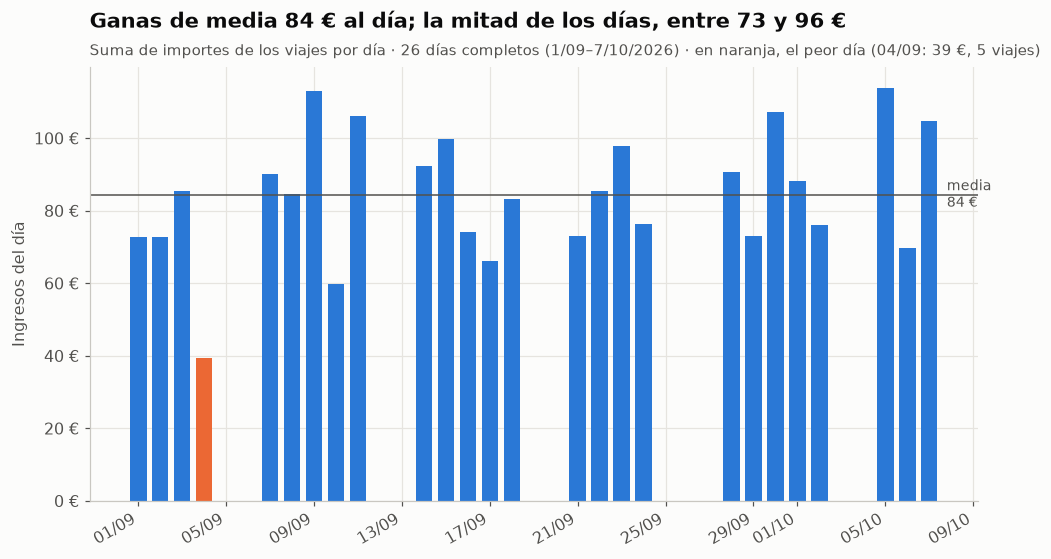

In [4]:
fig, ax = plt.subplots()
x = pd.to_datetime(dc.fecha)
peor = dc.loc[dc.ingresos_eur.idxmin()]
col = [NARANJA if f == peor.fecha else AZUL for f in dc.fecha]           # destacar solo el peor día
ax.bar(x, dc.ingresos_eur, color=col, width=0.75)
media = dc.ingresos_eur.mean()
ax.axhline(media, color=TINTA2, linewidth=1)
ax.text(x.iloc[-1] + pd.Timedelta(days=0.8), media, f"media\n{media:.0f} €", va="center", fontsize=9, color=TINTA2)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.yaxis.set_major_formatter(EURO)
ax.set_ylabel("Ingresos del día")
titulos(ax, f"Ganas de media {media:.0f} € al día; la mitad de los días, entre {dc.ingresos_eur.quantile(.25):.0f} y {dc.ingresos_eur.quantile(.75):.0f} €",
        f"Suma de importes de los viajes por día · {len(dc)} días completos (1/09–7/10/2026) · en naranja, el peor día "
        f"({pd.to_datetime(peor.fecha):%d/%m}: {peor.ingresos_eur:.0f} €, {peor.n_viajes} viajes)")
fig.autofmt_xdate()
guarda(fig, "01_ingresos_por_dia.png")

## Pregunta 1 · ¿Cuánto se gana por hora trabajada (bruto y neto)?

Solo hay **horas reales en 8 días** (app de la flota, 28/09–07/10). Uso dos definiciones de «hora trabajada»:
- **Tiempo total** de la jornada (lo más honesto: incluye recargas y esperas).
- **Tiempo efectivo** (lo que la flota cuenta como efectivo: conducción efectiva + recarga + cuidado).

El 02/10 se excluye (jornada no cerrada: sesión de 11,6 h con el último viaje a las 11:33). La cifra principal es el **cociente de sumas** (total € ÷ total de horas), que pesa más los días largos y es la forma correcta de promediar tasas.

> **«Bruto»** aquí es lo que la app llama ganancia de cada viaje. **No aparece ninguna comisión** en las capturas, así que no sé si ese importe ya descuenta la parte de VTC, ni qué parte te queda tras el reparto con la flota. **El neto no se puede calcular sin tus costes** → abajo hay una tabla de escenarios.

In [5]:
jh = jor.merge(dias[["fecha", "ingresos_eur", "n_viajes"]], on="fecha")
jh["horas_total"] = jh.tiempo_total_app_min / 60
jh["horas_efectivas"] = jh.tiempo_efectivo_min / 60
jh["eur_h_total"] = jh.ingresos_eur / jh.horas_total
jh["eur_h_efectivo"] = jh.ingresos_eur / jh.horas_efectivas
ok = jh[~jh.jornada_anomala]                                     # 7 jornadas normales

eur_h_total = ok.ingresos_eur.sum() / ok.horas_total.sum()       # cociente de sumas
eur_h_ef = ok.ingresos_eur.sum() / ok.horas_efectivas.sum()
ratio = lambda idx: ok.ingresos_eur.values[idx].sum() / ok.horas_total.values[idx].sum()
rng = np.random.default_rng(42)
sims = [ratio(rng.integers(0, len(ok), len(ok))) for _ in range(5000)]   # bootstrap por días
ic_h = np.percentile(sims, [2.5, 97.5])
con_anomalo = jh.ingresos_eur.sum() / jh.horas_total.sum()

metricas.update(eur_hora_tiempo_total=round(eur_h_total, 2), eur_hora_tiempo_efectivo=round(eur_h_ef, 2),
                ic95_eur_hora_total=[round(x, 2) for x in ic_h], eur_hora_total_incluyendo_02oct=round(con_anomalo, 2),
                jornadas_usadas_eur_hora=len(ok), horas_medias_jornada=round(ok.horas_total.mean(), 2))
print(f"€/hora sobre tiempo total:    {eur_h_total:.2f} €/h  (IC 95 %: {ic_h[0]:.2f} – {ic_h[1]:.2f}, n = {len(ok)} jornadas)")
print(f"€/hora sobre tiempo efectivo: {eur_h_ef:.2f} €/h")
print(f"Si se incluyera el 02/10:     {con_anomalo:.2f} €/h  (por eso se excluye: lo hunde un dato dudoso)")
print(f"Jornada típica: {ok.horas_total.mean():.1f} h totales, {ok.horas_efectivas.mean():.1f} h efectivas, {ok.n_viajes.mean():.1f} viajes")
jh[["fecha", "dia_semana", "n_viajes", "ingresos_eur", "horas_total", "horas_efectivas", "eur_h_total",
    "eur_h_efectivo", "jornada_anomala"]].round(2)

€/hora sobre tiempo total:    13.09 €/h  (IC 95 %: 11.24 – 14.71, n = 7 jornadas)
€/hora sobre tiempo efectivo: 15.36 €/h
Si se incluyera el 02/10:     11.70 €/h  (por eso se excluye: lo hunde un dato dudoso)
Jornada típica: 7.1 h totales, 6.0 h efectivas, 8.4 viajes


,fecha,dia_semana,n_viajes,ingresos_eur,horas_total,horas_efectivas,eur_h_total,eur_h_efectivo,jornada_anomala
0,2026-09-28,lunes,7,90.76,7.07,6.12,12.84,14.84,False
1,2026-09-29,martes,8,72.96,6.82,6.05,10.70,12.06,False
2,2026-09-30,miércoles,8,107.13,7.03,6.43,15.23,16.65,False
3,2026-10-01,jueves,11,88.33,6.30,5.55,14.02,15.92,False
4,2026-10-02,viernes,7,76.17,12.37,5.82,6.16,13.10,True
5,2026-10-05,lunes,10,113.84,7.45,5.97,15.28,19.08,False
6,2026-10-06,martes,8,69.66,7.77,6.00,8.97,11.61,False
7,2026-10-07,miércoles,7,104.66,7.03,6.02,14.88,17.40,False


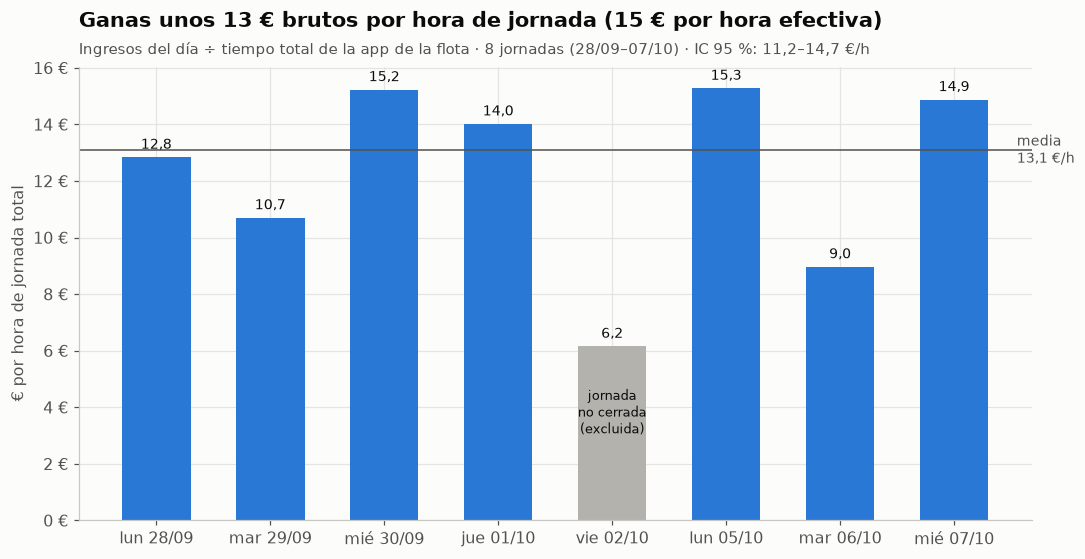

In [6]:
fig, ax = plt.subplots()
etiquetas = pd.to_datetime(jh.fecha).dt.strftime("%a %d/%m").str.replace("Mon", "lun").str.replace("Tue", "mar") \
              .str.replace("Wed", "mié").str.replace("Thu", "jue").str.replace("Fri", "vie")
colores = [GRIS if a else AZUL for a in jh.jornada_anomala]
ax.bar(etiquetas, jh.eur_h_total, color=colores, width=0.6)
ax.axhline(eur_h_total, color=TINTA2, linewidth=1)
ax.text(len(jh) - 0.45, eur_h_total, f"media\n{es(eur_h_total)} €/h", ha="left", va="center", fontsize=9, color=TINTA2)
for i, r in jh.iterrows():
    ax.text(i, r.eur_h_total + 0.3, es(r.eur_h_total), ha="center", fontsize=9, color=TINTA)
an = jh.index[jh.jornada_anomala][0]
ax.text(an, jh.eur_h_total[an] / 2, "jornada\nno cerrada\n(excluida)", ha="center", fontsize=8.5, color=TINTA)
ax.set_ylabel("€ por hora de jornada total")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:.0f} €"))
titulos(ax, f"Ganas unos {eur_h_total:.0f} € brutos por hora de jornada ({eur_h_ef:.0f} € por hora efectiva)",
        f"Ingresos del día ÷ tiempo total de la app de la flota · 8 jornadas (28/09–07/10) · IC 95 %: {es(ic_h[0])}–{es(ic_h[1])} €/h")
guarda(fig, "02_euros_por_hora.png")

### Neto: tabla de escenarios (hipotéticos, **no son datos**)

No tengo tus costes. En vez de inventarlos, calculo **qué pasaría** según dos cosas que tú sabes: qué **porcentaje** de lo facturado te queda (tras comisión/reparto con la flota) y cuántos **costes fijos semanales** pagas (alquiler, seguro…). Rellena `parametros_costes.csv` con tus cifras reales y vuelve a ejecutar: la última celda calcula tu neto real.

Fórmula: **neto/hora = (bruto/hora × % que te queda) − (costes fijos semanales ÷ horas por semana) − (combustible/energía por hora)**

In [7]:
semanas = pd.to_datetime(dc.fecha).dt.isocalendar().week.nunique()
dias_por_semana = len(dc) / semanas
horas_semana = ok.horas_total.mean() * dias_por_semana
print(f"Horas por semana estimadas: {ok.horas_total.mean():.2f} h/día × {dias_por_semana:.1f} días/semana = {horas_semana:.1f} h")

pct = [0.4, 0.5, 0.6, 0.7, 0.8, 1.0]
fijos = [0, 100, 200, 300]
tabla = pd.DataFrame({f"{f} €/sem": [eur_h_total * p - f / horas_semana for p in pct] for f in fijos},
                     index=[f"te queda {int(p*100)} %" for p in pct]).round(2)
metricas.update(horas_semana_estimadas=round(horas_semana, 1), dias_por_semana=round(dias_por_semana, 2))
print("Neto €/hora en cada escenario (sin energía; ESCENARIOS HIPOTÉTICOS):")
tabla

Horas por semana estimadas: 7.07 h/día × 4.3 días/semana = 30.6 h
Neto €/hora en cada escenario (sin energía; ESCENARIOS HIPOTÉTICOS):


,0 €/sem,100 €/sem,200 €/sem,300 €/sem
te queda 40 %,5.23,1.97,-1.30,-4.56
te queda 50 %,6.54,3.28,0.01,-3.25
te queda 60 %,7.85,4.59,1.32,-1.94
te queda 70 %,9.16,5.89,2.63,-0.64
te queda 80 %,10.47,7.20,3.94,0.67
te queda 100 %,13.09,9.82,6.56,3.29


In [8]:
# Si has rellenado parametros_costes.csv con tus datos reales, aquí sale tu neto.
par = pd.read_csv(BASE / "parametros_costes.csv").set_index("parametro").valor
if par.isna().any():
    print("parametros_costes.csv sin rellenar del todo -> no se calcula el neto real (no se inventan costes).")
    print(par[par.isna()].index.tolist())
else:
    neto_h = eur_h_total * par.porcentaje_que_te_queda / 100 - par.costes_fijos_semana_eur / horas_semana \
             - par.energia_eur_por_hora - par.otros_costes_eur_por_hora
    print(f"Tu neto estimado: {neto_h:.2f} €/hora")

parametros_costes.csv sin rellenar del todo -> no se calcula el neto real (no se inventan costes).
['porcentaje_que_te_queda', 'costes_fijos_semana_eur', 'energia_eur_por_hora', 'otros_costes_eur_por_hora']


## Pregunta 2 · ¿Qué días y franjas horarias son más rentables?

**Franjas:** atribuyo cada viaje a la hora en que empieza. Para cada día, considero «trabajada» cada hora entre la del primer y la del último viaje. Así calculo los **€ que genera de media cada hora de reloj en la que estás trabajando** (no solo cuando hay viaje).

In [9]:
filas = []
for _, d in dc.iterrows():                                        # para cada día completo
    h_ini, h_fin = int(d.primer_viaje[:2]), int(d.ultimo_viaje[:2])
    v_dia = vc[vc.fecha == d.fecha]
    for h in range(h_ini, h_fin + 1):                             # cada hora de la ventana de actividad
        v_h = v_dia[v_dia.hora_del_dia == h]
        filas.append(dict(fecha=d.fecha, dia_semana=d.dia_semana, hora=h, eur=v_h.importe_eur.sum(),
                          viajes=len(v_h), ceros=int(v_h.sin_ingreso.sum())))
horas = pd.DataFrame(filas)
franjas = horas.groupby("hora").agg(dias=("fecha", "count"), eur_medio=("eur", "mean"), eur_mediana=("eur", "median"),
                                    viajes_medios=("viajes", "mean"), pct_ceros=("ceros", "sum")).round(2)
franjas["pct_ceros"] = (franjas.pct_ceros / horas.groupby("hora").viajes.sum() * 100).round(1)
ics = horas.groupby("hora").eur.apply(lambda s: bootstrap_ic(s))
franjas["ic95_inf"] = [round(i[0], 1) for i in ics]
franjas["ic95_sup"] = [round(i[1], 1) for i in ics]
franjas.index = [f"{h:02d}:00" for h in franjas.index]
metricas["eur_por_franja"] = franjas.eur_medio.to_dict()
franjas

,dias,eur_medio,eur_mediana,viajes_medios,pct_ceros,ic95_inf,ic95_sup
06:00,14,16.56,14.90,1.64,8.7,12.5,21.1
07:00,24,17.72,18.62,1.75,14.3,14.5,20.9
08:00,26,22.46,18.27,1.50,12.8,17.1,28.2
09:00,26,17.92,17.75,1.54,17.5,13.6,22.3
10:00,26,11.79,12.00,1.27,15.2,8.7,15.0
11:00,18,8.65,7.04,1.06,5.3,5.6,12.6
12:00,7,3.80,6.00,1.14,50.0,1.2,6.3


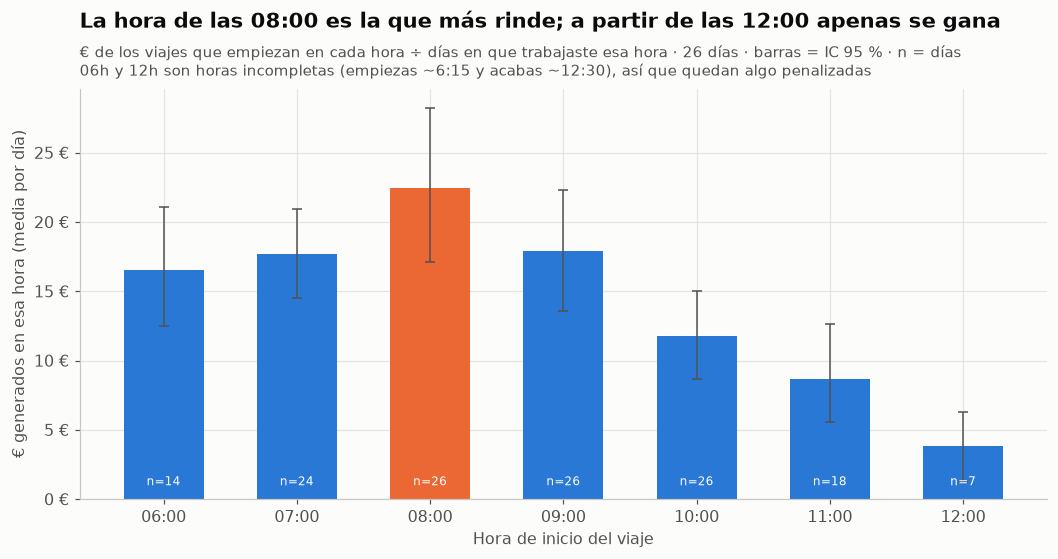

In [10]:
fig, ax = plt.subplots()
f = franjas[franjas.dias >= 5]                                    # solo franjas con al menos 5 días de muestra
mejor = f.eur_medio.idxmax()
col = [NARANJA if i == mejor else AZUL for i in f.index]
ax.bar(f.index, f.eur_medio, color=col, width=0.6)
ax.errorbar(range(len(f)), f.eur_medio, yerr=[f.eur_medio - f.ic95_inf, f.ic95_sup - f.eur_medio],
            fmt="none", ecolor=TINTA2, elinewidth=1, capsize=3)
for i, (idx, r) in enumerate(f.iterrows()):
    ax.text(i, 1, f"n={int(r.dias)}", ha="center", fontsize=8, color="white")
ax.yaxis.set_major_formatter(EURO)
ax.set_xlabel("Hora de inicio del viaje")
ax.set_ylabel("€ generados en esa hora (media por día)")
titulos(ax, f"La hora de las {mejor} es la que más rinde; a partir de las 12:00 apenas se gana",
        f"€ de los viajes que empiezan en cada hora ÷ días en que trabajaste esa hora · {len(dc)} días · barras = IC 95 % · n = días\n06h y 12h son horas incompletas (empiezas ~6:15 y acabas ~12:30), así que quedan algo penalizadas")
guarda(fig, "03_franjas_horarias.png")

**Días de la semana:** solo trabajas de lunes a viernes por la mañana, y hay 4–6 días de cada. Con tan pocos días, miramos si los intervalos de confianza se solapan.

In [11]:
orden = ["lunes", "martes", "miércoles", "jueves", "viernes"]
sem = dc.groupby("dia_semana").ingresos_eur.agg(dias="count", media="mean", mediana="median", desv="std").reindex(orden)
sem[["ic95_inf", "ic95_sup"]] = [bootstrap_ic(dc.loc[dc.dia_semana == d, "ingresos_eur"]) for d in orden]
sem = sem.round(1)
metricas["ingreso_medio_por_dia_semana"] = sem.media.to_dict()
sem

,dias,media,mediana,desv,ic95_inf,ic95_sup
dia_semana,,,,,,
lunes,5,92.0,90.8,14.6,80.4,104.5
martes,6,80.9,78.7,11.4,73.4,89.9
miércoles,6,94.9,101.3,17.4,82.4,107.2
jueves,5,75.2,76.2,12.2,65.7,84.8
viernes,4,76.3,79.7,27.7,50.4,98.7


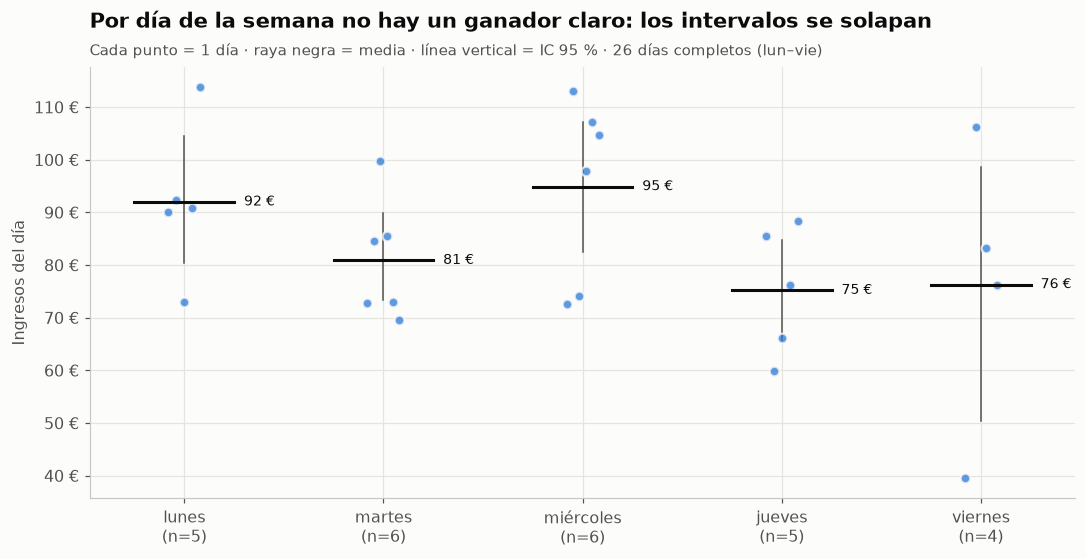

In [12]:
fig, ax = plt.subplots()
for i, d in enumerate(orden):
    vals = dc.loc[dc.dia_semana == d, "ingresos_eur"]
    ax.scatter(np.full(len(vals), i) + np.linspace(-0.08, 0.08, len(vals)), vals, color=AZUL, s=40, alpha=0.75, zorder=3,
               edgecolor="#fcfcfb", linewidth=1.5)
    ax.plot([i - 0.25, i + 0.25], [sem.media[d]] * 2, color=TINTA, linewidth=2, zorder=4)
    ax.plot([i, i], [sem.ic95_inf[d], sem.ic95_sup[d]], color=TINTA2, linewidth=1, zorder=2)
    ax.text(i + 0.3, sem.media[d], f"{sem.media[d]:.0f} €", va="center", fontsize=9, color=TINTA)
ax.set_xticks(range(5), [f"{d}\n(n={int(sem.dias[d])})" for d in orden])
ax.yaxis.set_major_formatter(EURO)
ax.set_ylabel("Ingresos del día")
titulos(ax, "Por día de la semana no hay un ganador claro: los intervalos se solapan",
        "Cada punto = 1 día · raya negra = media · línea vertical = IC 95 % · 26 días completos (lun–vie)")
guarda(fig, "04_dia_semana.png")

**Mapa de calor día × hora** (€ medios por hora trabajada). Ojo: cada casilla tiene solo 4–6 días detrás; sirve para ver patrones, no para afirmar diferencias.

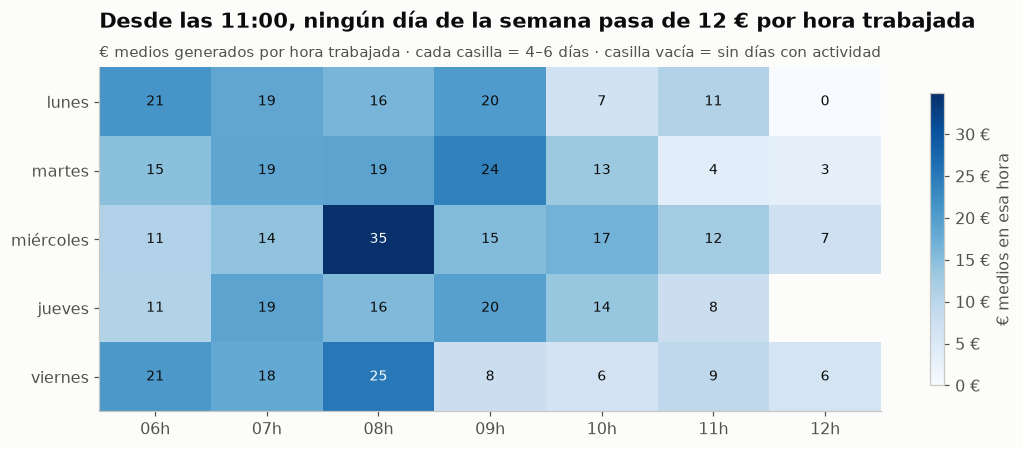

In [13]:
mapa = horas.pivot_table(index="dia_semana", columns="hora", values="eur", aggfunc="mean").reindex(orden)
mapa = mapa[[h for h in mapa.columns if h <= 12]]
fig, ax = plt.subplots(figsize=(10, 4.2))
im = ax.imshow(mapa.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(len(mapa.columns)), [f"{h:02d}h" for h in mapa.columns])
ax.set_yticks(range(len(orden)), orden)
ax.grid(False)
for (i, j), val in np.ndenumerate(mapa.values):
    if not np.isnan(val):
        ax.text(j, i, f"{val:.0f}", ha="center", va="center", fontsize=9, color="white" if val > 25 else TINTA)
cb = fig.colorbar(im, ax=ax, format=EURO, shrink=0.85)
cb.set_label("€ medios en esa hora")
titulos(ax, "Desde las 11:00, ningún día de la semana pasa de 12 € por hora trabajada",
        "€ medios generados por hora trabajada · cada casilla = 4–6 días · casilla vacía = sin días con actividad")
guarda(fig, "05_mapa_dia_hora.png")

## Pregunta 3 · ¿Qué zonas rinden más?

**No se puede responder con estos datos**: el historial no muestra direcciones ni zonas. Lo único que se acerca es el tipo de servicio **VTC Airport** (viajes con origen o destino en el aeropuerto).

In [14]:
aer = vc[~vc.sin_ingreso].groupby("es_aeropuerto").importe_eur.agg(viajes="count", media="mean", mediana="median").round(2)
aer.index = ["Resto", "Aeropuerto"]
aer["% de ingresos"] = (vc.groupby("es_aeropuerto").importe_eur.sum().values / vc.importe_eur.sum() * 100).round(1)
ceros_aer = vc.groupby("es_aeropuerto").sin_ingreso.mean().mul(100).round(1).values
aer["% viajes a 0 €"] = ceros_aer
metricas.update(ticket_medio_aeropuerto=aer.loc["Aeropuerto", "media"], ticket_medio_resto=aer.loc["Resto", "media"])
aer

,viajes,media,mediana,% de ingresos,% viajes a 0 €
Resto,150,11.86,10.30,81.0,15.3
Aeropuerto,24,17.39,15.92,19.0,11.1


## Pregunta 4 · ¿Cuánto tiempo muerto tengo y cuánto cuesta?

Con las 7 jornadas normales, desgloso cada jornada en:
- **Conducción efectiva** (la app de la flota no aclara si incluye los trayectos vacíos hasta el pasajero; casi seguro que sí).
- **Recarga eléctrica** y **cuidado del vehículo**.
- **Conducción no efectiva** (conduciendo pero sin estar disponible).
- **Sin clasificar**: minutos de la sesión que la app no asigna a nada → probablemente **esperas con el coche parado**.

**Coste:** si ese tiempo rindiera como tu conducción efectiva (ingresos ÷ horas de conducción efectiva), ¿cuánto dejarías de ganar? Es un **coste de oportunidad máximo**: supone que habría demanda para llenarlo.

> **Coste de oportunidad:** lo que dejas de ganar por usar el tiempo en otra cosa.

In [15]:
partes = ["conduccion_efectiva_min", "recarga_electrica_min", "cuidado_vehiculo_min", "conduccion_no_efectiva_min", "sin_clasificar_min"]
nombres = ["Conducción efectiva", "Recarga eléctrica", "Cuidado del vehículo", "Conducción no efectiva", "Sin clasificar (esperas)"]
desg = ok[["fecha"] + partes].set_index("fecha")
medio = desg.mean().round(1)
muerto_min = medio[partes[1:]].sum()
eur_h_conduccion = ok.ingresos_eur.sum() / (ok.conduccion_efectiva_min.sum() / 60)
coste_dia = muerto_min / 60 * eur_h_conduccion
metricas.update(min_muertos_dia=round(muerto_min, 1), pct_muerto=round(muerto_min / ok.tiempo_total_app_min.mean() * 100, 1),
                recarga_media_min=round(medio.recarga_electrica_min, 1), sin_clasificar_medio_min=round(medio.sin_clasificar_min, 1),
                eur_h_conduccion_efectiva=round(eur_h_conduccion, 2), coste_oportunidad_dia=round(coste_dia, 2))
print(pd.DataFrame({"min/día (media)": medio.values}, index=nombres))
print(f"\nTiempo sin conducción efectiva: {muerto_min:.0f} min/día = {metricas['pct_muerto']} % de la jornada")
print(f"€/hora de conducción efectiva: {eur_h_conduccion:.2f} € -> coste de oportunidad máx.: {coste_dia:.0f} €/día "
      f"(≈ {coste_dia * dias_por_semana:.0f} €/semana)")

                          min/día (media)
Conducción efectiva                 315.9
Recarga eléctrica                    35.3
Cuidado del vehículo                 10.0
Conducción no efectiva                7.0
Sin clasificar (esperas)             56.4

Tiempo sin conducción efectiva: 109 min/día = 25.6 % de la jornada
€/hora de conducción efectiva: 17.57 € -> coste de oportunidad máx.: 32 €/día (≈ 138 €/semana)


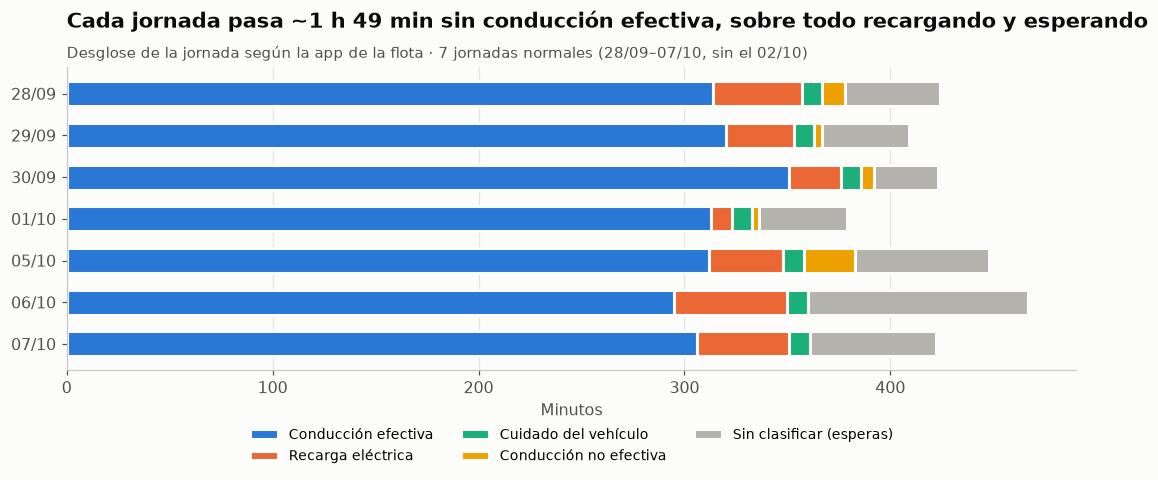

In [16]:
fig, ax = plt.subplots(figsize=(10, 4.6))
cols = [AZUL, NARANJA, AQUA, AMARILLO, GRIS]
izq = np.zeros(len(desg))
etq = pd.to_datetime(desg.index).strftime("%d/%m")
for p, nom, c in zip(partes, nombres, cols):
    ax.barh(etq, desg[p], left=izq, color=c, label=nom, height=0.6, edgecolor="#fcfcfb", linewidth=2)
    izq += desg[p].values
ax.invert_yaxis()
ax.set_xlabel("Minutos")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False, fontsize=9)
ax.grid(axis="y", visible=False)
titulos(ax, f"Cada jornada pasa ~{round(muerto_min) // 60} h {round(muerto_min) % 60} min sin conducción efectiva, sobre todo recargando y esperando",
        "Desglose de la jornada según la app de la flota · 7 jornadas normales (28/09–07/10, sin el 02/10)")
guarda(fig, "06_desglose_jornada.png")

In [17]:
# Esperas entre viajes: minutos entre el inicio de un viaje y el siguiente (incluye la duración del viaje)
esp = vc.min_hasta_siguiente.dropna()
print(f"Minutos entre inicios de viajes consecutivos: mediana {esp.median():.0f}, P25 {esp.quantile(.25):.0f}, "
      f"P75 {esp.quantile(.75):.0f}, máx {esp.max():.0f} (n = {len(esp)})")
print("Huecos de más de 60 min:", int((esp > 60).sum()), f"({(esp > 60).mean() * 100:.0f} %)")
metricas.update(mediana_min_entre_viajes=round(esp.median(), 0))

Minutos entre inicios de viajes consecutivos: mediana 33, P25 22, P75 54, máx 115 (n = 178)
Huecos de más de 60 min: 34 (19 %)


## Pregunta 5 · ¿Plataforma frente a Uber?

**No se puede responder: no hay ningún dato de Uber.** Como alternativa, comparo los **tipos de servicio de la plataforma** entre sí.

In [18]:
tipos = vc.groupby("producto").agg(viajes=("id_viaje", "count"), ingresos=("importe_eur", "sum"),
                                   importe_medio=("importe_eur", "mean"), pct_a_0=("sin_ingreso", "mean"))
tipos["importe_medio_sin_ceros"] = vc[~vc.sin_ingreso].groupby("producto").importe_eur.mean()
tipos["pct_a_0"] = (tipos.pct_a_0 * 100).round(1)
tipos = tipos.sort_values("viajes", ascending=False).round(2)
tipos

,viajes,ingresos,importe_medio,pct_a_0,importe_medio_sin_ceros
producto,,,,,
VTC,130,1307.93,10.06,13.8,11.68
VTC Airport,27,417.37,15.46,11.1,17.39
VTC Eco,19,209.59,11.03,21.1,13.97
VTC Prioritario,16,120.37,7.52,25.0,10.03
Electric,7,70.91,10.13,14.3,11.82
VTC Promo,3,48.35,16.12,0.0,16.12
Desconocido,1,6.55,6.55,0.0,6.55
Envíos en coche,1,14.62,14.62,0.0,14.62


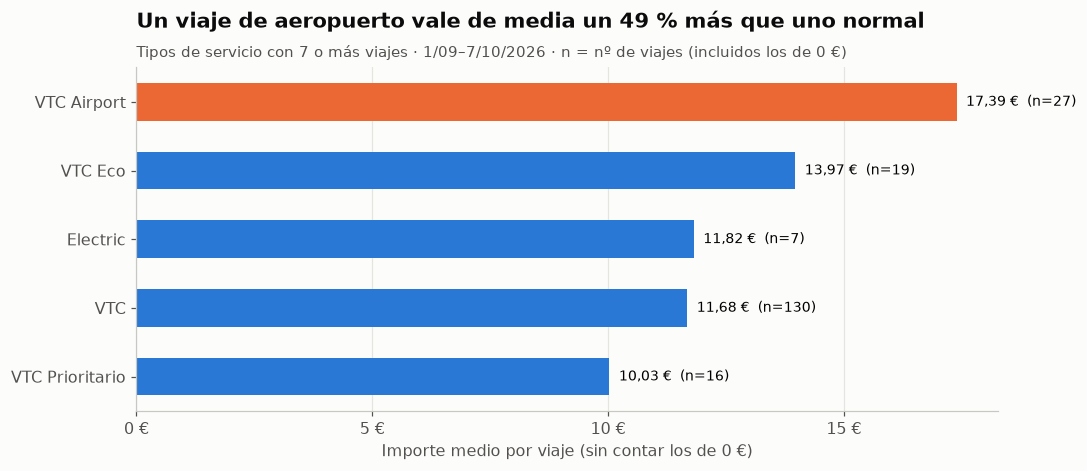

In [19]:
t = tipos[tipos.viajes >= 7].sort_values("importe_medio_sin_ceros")     # solo tipos con 7 o más viajes
fig, ax = plt.subplots(figsize=(10, 4.4))
col = [NARANJA if i == "VTC Airport" else AZUL for i in t.index]
ax.barh(t.index, t.importe_medio_sin_ceros, color=col, height=0.55)
for i, (idx, r) in enumerate(t.iterrows()):
    ax.text(r.importe_medio_sin_ceros + 0.2, i, f"{es(r.importe_medio_sin_ceros, 2)} €  (n={int(r.viajes)})", va="center", fontsize=9)
ax.xaxis.set_major_locator(mtick.MultipleLocator(5))
ax.xaxis.set_major_formatter(EURO)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Importe medio por viaje (sin contar los de 0 €)")
base = t.importe_medio_sin_ceros["VTC"]
titulos(ax, f"Un viaje de aeropuerto vale de media un {(t.importe_medio_sin_ceros['VTC Airport'] / base - 1) * 100:.0f} % más que uno normal",
        "Tipos de servicio con 7 o más viajes · 1/09–7/10/2026 · n = nº de viajes (incluidos los de 0 €)")
guarda(fig, "07_tipos_servicio.png")

## Pregunta 6 · ¿Qué efecto tienen propinas, cancelaciones y peajes?

In [20]:
g = lambda c, p: app.loc[(app.concepto == c) & (app.periodo == p), "valor"].sum()
efectos = pd.DataFrame({
    "Septiembre": [g("propinas", "2026-09"), g("peajes", "2026-09"), g("incentivos", "2026-09"), g("ganancia_mensual", "2026-09")],
    "Octubre (1–7)": [g("propinas", "2026-10"), g("peajes", "2026-10"), g("incentivos", "2026-10"), g("ganancia_mensual", "2026-10")]},
    index=["Propinas (€)", "Peajes (€, reembolso)", "Incentivos (€)", "Ganancia del mes (€)"])
efectos.loc["Propinas + incentivos, % de la ganancia"] = ((efectos.iloc[0] + efectos.iloc[2]) / efectos.iloc[3] * 100).round(2)
efectos

,Septiembre,Octubre (1–7)
Propinas (€),4.00,0.00
"Peajes (€, reembolso)",5.00,6.00
Incentivos (€),8.00,3.00
Ganancia del mes (€),1746.03,449.66
"Propinas + incentivos, % de la ganancia",0.69,0.67


In [21]:
n0, n6 = int(vc.sin_ingreso.sum()), int(vc.importe_6_exactos.sum())
ult_semana = viajes[(viajes.fecha >= "2026-10-01")]
canc_app = app.set_index("concepto").valor
print(f"Viajes a 0 € (probables cancelaciones): {n0} de {len(vc)} = {n0 / len(vc) * 100:.1f} %")
print(f"Viajes de 6 € exactos (importe mínimo):  {n6} de {len(vc)} = {n6 / len(vc) * 100:.1f} %")
print(f"Según la app, la última semana: {canc_app['viajes_totales_ult_semana']:.0f} viajes, "
      f"{canc_app['cancelacion_forzosa_pasajero_ult_semana']:.0f} cancelaciones forzosas del pasajero "
      f"(tasa de finalización {canc_app['tasa_finalizacion_ult_semana']:.0f} %)")
print("\n% de viajes a 0 € por hora de inicio:")
print((vc.groupby("hora_del_dia").sin_ingreso.mean() * 100).round(0).astype(int).to_string())
metricas.update(viajes_0_eur=n0, pct_viajes_0_eur=round(n0 / len(vc) * 100, 1), viajes_6_eur=n6,
                pct_viajes_6_eur=round(n6 / len(vc) * 100, 1))

Viajes a 0 € (probables cancelaciones): 30 de 204 = 14.7 %
Viajes de 6 € exactos (importe mínimo):  27 de 204 = 13.2 %
Según la app, la última semana: 38 viajes, 4 cancelaciones forzosas del pasajero (tasa de finalización 89 %)

% de viajes a 0 € por hora de inicio:
hora_del_dia
6      9
7     14
8     13
9     18
10    15
11     5
12    50


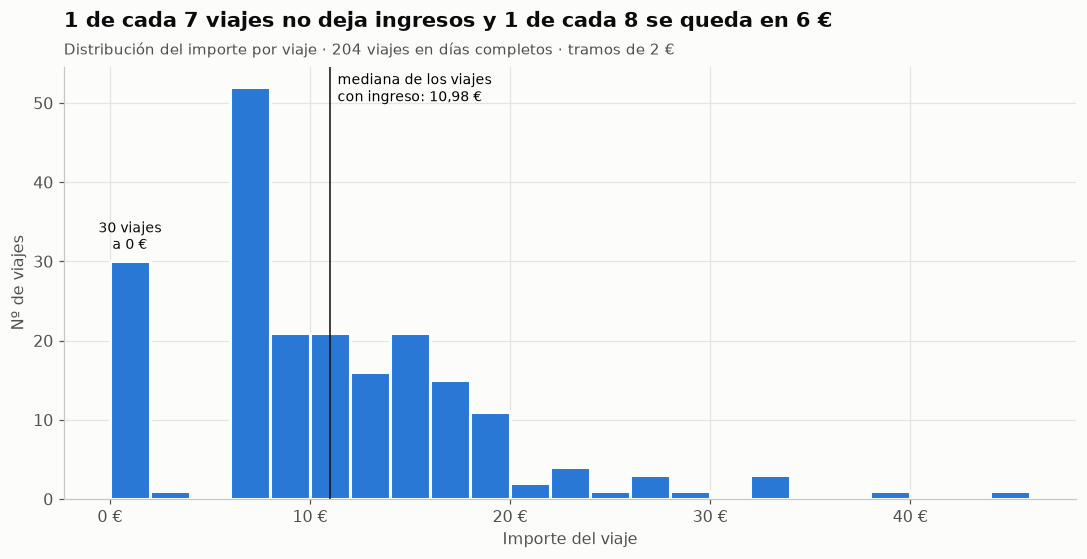

In [22]:
fig, ax = plt.subplots()
bins = np.arange(0, 48, 2)
ax.hist(vc.importe_eur, bins=bins, color=AZUL, edgecolor="#fcfcfb", linewidth=2)
ax.axvline(con_ingreso.median(), color=TINTA, linewidth=1)
ax.text(con_ingreso.median() + 0.4, ax.get_ylim()[1] * 0.92, f"mediana de los viajes\ncon ingreso: {es(con_ingreso.median(), 2)} €", fontsize=9)
ax.text(1, n0 + 1, f"{n0} viajes\na 0 €", ha="center", va="bottom", fontsize=9, color=TINTA)
ax.xaxis.set_major_formatter(EURO)
ax.set_xlabel("Importe del viaje")
ax.set_ylabel("Nº de viajes")
titulos(ax, f"1 de cada {round(len(vc) / n0)} viajes no deja ingresos y 1 de cada {round(len(vc) / n6)} se queda en 6 €",
        f"Distribución del importe por viaje · {len(vc)} viajes en días completos · tramos de 2 €")
guarda(fig, "08_distribucion_importes.png")

**Efectivo frente a app** (pregunta extra):

In [23]:
pago = vc.groupby("metodo_pago").agg(viajes=("id_viaje", "count"), importe_medio=("importe_eur", "mean"),
                                     total=("importe_eur", "sum")).round(2)
pago["% viajes"] = (pago.viajes / pago.viajes.sum() * 100).round(1)
pago

,viajes,importe_medio,total,% viajes
metodo_pago,,,,
app,184,10.95,2015.29,90.2
efectivo,20,9.02,180.40,9.8


## Pregunta 7 · ¿Qué cambiaría en el horario para ganar más por hora?

Juntando lo anterior:
1. **Las horas fuertes son 8:00–9:59.** Las 12:00 rinden muy poco (ver tabla de franjas).
2. **Recarga + esperas** se comen más de 1 h por jornada.
3. **La noche es una incógnita prometedora**: la única noche registrada (lunes 31/08, 21:23–23:26) dejó 84 € en 8 viajes en ~2 h de ventana. Es **un solo día**: no prueba nada, pero merece un experimento.

Comparo la «ventana de actividad» (del primer al último viaje) para poder poner la noche al lado de las mañanas. Esta medida **sobrestima** el €/hora (no cuenta la espera antes del primer viaje ni la duración del último), pero sirve para comparar igual con igual.

In [24]:
noche = dias[dias.fecha == "2026-08-31"].iloc[0]
manana = dc.ingresos_eur / dc.ventana_actividad_h
print(f"Mañanas (n={len(dc)}): {manana.median():.1f} €/h de ventana (mediana), P25–P75 {manana.quantile(.25):.1f}–{manana.quantile(.75):.1f}")
print(f"Noche del 31/08 (n=1): {noche.ingresos_eur / noche.ventana_actividad_h:.1f} €/h de ventana "
      f"({noche.ingresos_eur:.2f} € en {noche.n_viajes} viajes, de {noche.primer_viaje} a {noche.ultimo_viaje})")
ult = franjas.loc["12:00"] if "12:00" in franjas.index else None
print(f"\nLa franja de las 12:00 genera de media {franjas.loc['12:00', 'eur_medio']:.1f} € por hora trabajada "
      f"frente a {franjas.loc[mejor, 'eur_medio']:.1f} € la de las {mejor}.")
metricas.update(eur_h_ventana_mananas_mediana=round(manana.median(), 1),
                eur_h_ventana_noche_31ago=round(noche.ingresos_eur / noche.ventana_actividad_h, 1),
                franja_mejor=mejor)

Mañanas (n=26): 19.7 €/h de ventana (mediana), P25–P75 17.3–21.0
Noche del 31/08 (n=1): 41.1 €/h de ventana (84.27 € en 8 viajes, de 21:23 a 23:26)

La franja de las 12:00 genera de media 3.8 € por hora trabajada frente a 22.5 € la de las 08:00.


**El tramo final de la jornada.** En las 7 jornadas con horas, ¿cuánto se gana desde las 11:00 hasta que se cierra la sesión? (Cuidado: un viaje que empieza a las 10:50 y acaba a las 11:20 cuenta antes de las 11; y en ese tramo puede haber tareas obligatorias, como devolver el coche o recargar. La app no lo dice.)

In [25]:
tramo = []
for _, r in ok.iterrows():
    v_dia = viajes[viajes.fecha == r.fecha]
    fin_ = pd.to_datetime(r.fecha + " " + r.fin)
    ini_ = pd.to_datetime(r.fecha + " " + r.inicio)
    once = pd.to_datetime(r.fecha + " 11:00")
    tramo.append(dict(fecha=r.fecha, fin=r.fin,
                      eur_antes_11=v_dia[v_dia.hora < "11:00"].importe_eur.sum(), h_antes_11=(once - ini_).total_seconds() / 3600,
                      eur_desde_11=v_dia[v_dia.hora >= "11:00"].importe_eur.sum(), h_desde_11=(fin_ - once).total_seconds() / 3600))
tramo = pd.DataFrame(tramo).round(2)
e11, h11 = tramo.eur_desde_11.sum(), tramo.h_desde_11.sum()
print(f"Desde las 11:00 hasta el cierre: {e11:.2f} € en {h11:.1f} h de sesión -> {e11 / h11:.2f} €/h "
      f"({e11 / len(tramo):.2f} € por día, {h11 / len(tramo) * 60:.0f} min por día)")
print(f"Antes de las 11:00: {tramo.eur_antes_11.sum() / tramo.h_antes_11.sum():.2f} €/h de sesión")
sin_tramo = (ok.ingresos_eur.sum() - e11) / (ok.horas_total.sum() - h11)
print(f"€/hora de jornada si se quitara ese tramo: {sin_tramo:.2f} € (ahora {eur_h_total:.2f} €)")
metricas.update(eur_dia_desde_11=round(e11 / len(tramo), 2), eur_h_desde_11=round(e11 / h11, 2),
                min_dia_desde_11=round(h11 / len(tramo) * 60), eur_h_sin_tramo_final=round(sin_tramo, 2),
                eur_h_sesion_antes_11=round(tramo.eur_antes_11.sum() / tramo.h_antes_11.sum(), 2))
tramo

Desde las 11:00 hasta el cierre: 44.17 € en 11.4 h de sesión -> 3.87 €/h (6.31 € por día, 98 min por día)
Antes de las 11:00: 18.36 €/h de sesión
€/hora de jornada si se quitara ese tramo: 15.85 € (ahora 13.09 €)


,fecha,fin,eur_antes_11,h_antes_11,eur_desde_11,h_desde_11
0,2026-09-28,12:26,78.21,4.75,12.55,1.43
1,2026-09-29,12:17,66.96,4.82,6.00,1.28
2,2026-09-30,12:45,107.13,4.72,0.00,1.75
3,2026-10-01,12:22,81.25,4.62,7.08,1.37
4,2026-10-05,13:02,102.00,4.67,11.84,2.03
5,2026-10-06,13:04,62.96,4.63,6.70,2.07
6,2026-10-07,12:28,104.66,4.65,0.00,1.47


## Lo mismo en SQL

Las consultas clave también están en `consultas.sql` (se ejecutan con `scripts/ejecutar_sql.py`). Aquí compruebo que SQL y pandas dan **lo mismo**: es una buena forma de verificar un análisis.

In [26]:
con = sqlite3.connect(":memory:")                         # base de datos SQLite temporal en memoria
vc.to_sql("viajes", con, index=False)                      # copiar la tabla de pandas a SQL
sql = """
SELECT dia_semana,
       COUNT(DISTINCT fecha)                          AS dias,
       ROUND(SUM(importe_eur) / COUNT(DISTINCT fecha), 2) AS ingreso_medio_dia
FROM viajes
GROUP BY dia_semana
ORDER BY ingreso_medio_dia DESC;
"""
r_sql = pd.read_sql(sql, con).set_index("dia_semana")
comparacion = r_sql.join(sem.media.rename("pandas"))
print(comparacion)
assert np.allclose(comparacion.ingreso_medio_dia, comparacion.pandas, atol=0.06)
print("✔ SQL y pandas coinciden")

            dias  ingreso_medio_dia  pandas
dia_semana                                 
miércoles      6              94.91    94.9
lunes          5              91.98    92.0
martes         6              80.86    80.9
viernes        4              76.26    76.3
jueves         5              75.23    75.2
✔ SQL y pandas coinciden


In [27]:
# Guardar cifras clave (las usan el informe, el dashboard y el control de calidad)
def limpia(o):
    if isinstance(o, dict): return {str(k): limpia(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [limpia(x) for x in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return round(float(o), 2)
    return o
(LIMPIOS / "metricas_clave.json").write_text(json.dumps(limpia(metricas), ensure_ascii=False, indent=2))
print(json.dumps(limpia(metricas), ensure_ascii=False, indent=1)[:1500])

{
 "dias_completos": 26,
 "viajes_dias_completos": 204,
 "ingresos_total_dias_completos": 2195.69,
 "ingreso_medio_dia": 84.45,
 "ingreso_mediano_dia": 84.99,
 "ic95_ingreso_medio_dia": [
  77.81,
  91.05
 ],
 "viajes_medios_dia": 7.85,
 "ticket_medio_con_ingreso": 12.62,
 "ticket_mediano_con_ingreso": 10.98,
 "eur_hora_tiempo_total": 13.09,
 "eur_hora_tiempo_efectivo": 15.36,
 "ic95_eur_hora_total": [
  11.24,
  14.71
 ],
 "eur_hora_total_incluyendo_02oct": 11.7,
 "jornadas_usadas_eur_hora": 7,
 "horas_medias_jornada": 7.07,
 "horas_semana_estimadas": 30.6,
 "dias_por_semana": 4.33,
 "eur_por_franja": {
  "06:00": 16.56,
  "07:00": 17.72,
  "08:00": 22.46,
  "09:00": 17.92,
  "10:00": 11.79,
  "11:00": 8.65,
  "12:00": 3.8
 },
 "ingreso_medio_por_dia_semana": {
  "lunes": 92.0,
  "martes": 80.9,
  "miércoles": 94.9,
  "jueves": 75.2,
  "viernes": 76.3
 },
 "ticket_medio_aeropuerto": 17.39,
 "ticket_medio_resto": 11.86,
 "min_muertos_dia": 108.7,
 "pct_muerto": 25.6,
 "recarga_media_mi

## Conclusiones (con su tamaño de muestra)

Ver `RESUMEN_EJECUTIVO.md` para la versión de una página. Lo esencial:
- **€/hora bruto ≈ 13 €** por hora de jornada (≈ 15 € por hora efectiva). n = 7 jornadas: es una estimación con margen (ver IC).
- **La franja de 8 a 10 h** es la más productiva; **las 12:00** apenas aportan.
- **Por día de la semana no hay diferencias claras** con 4–6 días por grupo.
- **~1 h 49 min por jornada** (26 %) no es conducción efectiva (recarga, esperas).
- **15 % de los viajes acaban a 0 €** y otro 13 % en el mínimo de 6 €.
- **No se puede**: neto real (faltan costes), zonas (faltan direcciones), Uber (faltan datos).